# Modelagem preditiva e avaliação de classificadores (TDE01ML.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `TDE01ML.ipynb`  

---


Alunos: Victor Silva Camargo,Vinícius Silva Camargo


In [ ]:
# 1 importing the necessary classes / methods
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_digits, load_breast_cancer
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score


KNN Cross-Validation com Load Digits

In [ ]:
# Loading the dataset
X, y = load_digits(return_X_y=True)


In [ ]:
# Model declaration
clf=KNeighborsClassifier(n_neighbors=1, algorithm='ball_tree', weights='distance', p=2)


In [ ]:
# Model training and evaluation
N_folds = 10
result = cross_val_score(clf, X, y, cv = N_folds)
print('Taxa de acerto (acurácia) media: ' , result.mean() * 100)
print('Taxa de acerto (acurácia) std: ' , result.std() * 100)


Taxa de acerto (acurácia) media:  97.49627560521415
Taxa de acerto (acurácia) std:  1.7080387704964954


Precision score:  97.5306765352967
Recall score:  97.50209362842311
F1 score:  97.50209362842311


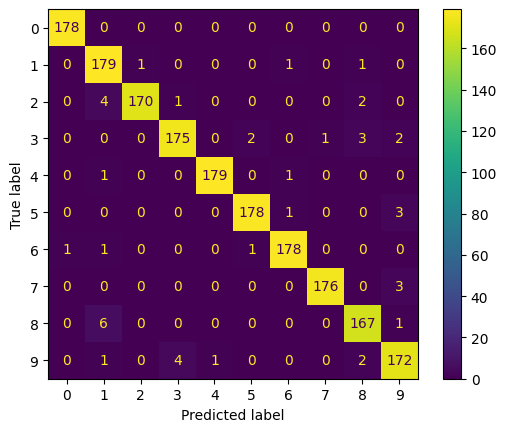

In [ ]:
# Test prediction
ypred = cross_val_predict(clf, X, y, cv = N_folds)

# Ploting the confusion matrix
cm = confusion_matrix(y, ypred)

disp = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= [0,1,2,3,4,5,6,7,8,9])
disp.plot()

# Precision
print('Precision score: ', precision_score(y, ypred, average='weighted') * 100)

# Recall
print('Recall score: ', f1_score(y, ypred, average='weighted') * 100)

# F1 score
print('F1 score: ', f1_score(y, ypred, average='weighted') * 100)


KNN Cross-Validation com Breast Cancer

In [ ]:
# Loading the dataset
X, y = load_breast_cancer(return_X_y=True)

In [ ]:
# Model declaration
clf=KNeighborsClassifier(n_neighbors=1, algorithm='ball_tree', weights='distance', p=2)


In [ ]:
# Model training and evaluation
N_folds = 10
result = cross_val_score(clf, X, y, cv = N_folds)
print('Taxa de acerto (acurácia) media: ' , result.mean() * 100)
print('Taxa de acerto (acurácia) std: ' , result.std() * 100)


Taxa de acerto (acurácia) media:  91.56954887218045
Taxa de acerto (acurácia) std:  3.0086428167942683


Precision score:  91.54580136311031
Recall score:  91.51101319660148
F1 score:  91.51101319660148


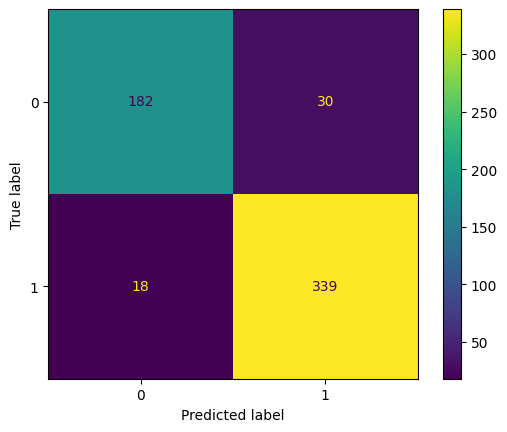

In [ ]:
# Test prediction
ypred = cross_val_predict(clf, X, y, cv = N_folds)

# Ploting the confusion matrix
cm = confusion_matrix(y, ypred)

disp = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= [0,1])
disp.plot()

# Precision
print('Precision score: ', precision_score(y, ypred, average='weighted') * 100)

# Recall
print('Recall score: ', f1_score(y, ypred, average='weighted') * 100)

# F1 score
print('F1 score: ', f1_score(y, ypred, average='weighted') * 100)


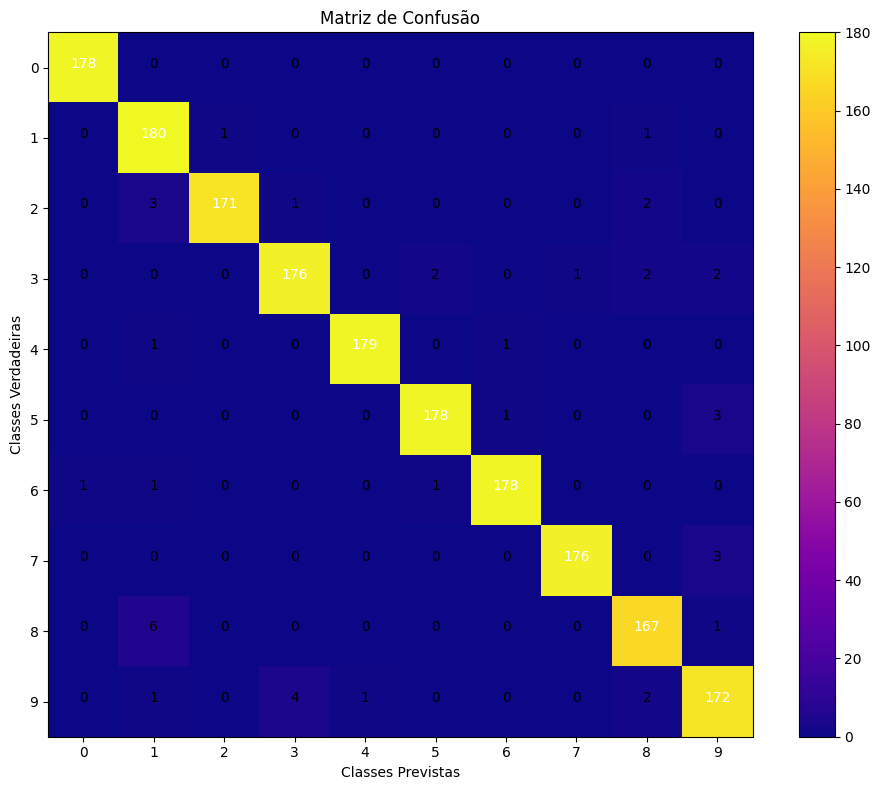

Acurácia média: 97.66%
Precisão média: 97.70%
Recall médio: 97.66%
F1 Score médio: 97.67%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import KFold
from collections import Counter

# 1. Carregar a base de dados
X, y = load_digits(return_X_y=True)

# 2. Implementar a lógica do classificador KNN
def euclidean_distance_squared(a, b):
    return np.sum((a - b) ** 2)

def knn_predict(X_train, y_train, X_test, k=1):
    predictions = []

    for test_point in X_test:
        # Calcular distâncias ao quadrado para todos os pontos de treinamento
        distances = [euclidean_distance_squared(test_point, train_point) for train_point in X_train]

        # Encontrar os k vizinhos mais próximos
        k_indices = np.argsort(distances)[:k]

        # Obter os rótulos dos vizinhos
        k_nearest_labels = [y_train[i] for i in k_indices]

        # Fazer a previsão com base na maioria dos votos
        most_common = Counter(k_nearest_labels).most_common(1)
        predictions.append(most_common[0][0])

    return np.array(predictions)

# 3. Dividir o conjunto de dados em 10 folds
kf = KFold(n_splits=10)

# 4. Avaliar o modelo com validação cruzada
all_predictions = []
all_true_labels = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Prever as classes para o conjunto de teste
    y_pred = knn_predict(X_train, y_train, X_test, k=1)  # k=1 para KNN
    all_predictions.extend(y_pred)
    all_true_labels.extend(y_test)

# 5. Calcular métricas de desempenho
all_predictions = np.array(all_predictions)
all_true_labels = np.array(all_true_labels)

# Matriz de confusão
confusion_matrix = np.zeros((10, 10), dtype=int)
for true, pred in zip(all_true_labels, all_predictions):
    confusion_matrix[true, pred] += 1

# 6. Plotar a matriz de confusão
plt.figure(figsize=(10, 8))
plt.imshow(confusion_matrix, interpolation='nearest', cmap='plasma')  # Usando a coloração de roxo a amarelo
plt.title('Matriz de Confusão')
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, tick_marks)
plt.yticks(tick_marks, tick_marks)

# Adicionar rótulos aos eixos
plt.xlabel('Classes Previstas')
plt.ylabel('Classes Verdadeiras')

# Adicionar os valores na matriz
thresh = confusion_matrix.max() / 2.
for i, j in np.ndindex(confusion_matrix.shape):
    plt.text(j, i, format(confusion_matrix[i, j], 'd'),
             horizontalalignment="center",
             color="white" if confusion_matrix[i, j] > thresh else "black")

plt.tight_layout()
plt.show()

# 7. Calcular precisão, recall e F1 score
precision = np.diag(confusion_matrix) / np.sum(confusion_matrix, axis=0)  # Precision para cada classe
recall = np.diag(confusion_matrix) / np.sum(confusion_matrix, axis=1)  # Recall para cada classe
f1_scores = 2 * (precision * recall) / (precision + recall)

# 8. Mostrar resultados
print('Acurácia média: {:.2f}%'.format(np.mean(all_predictions == all_true_labels) * 100))
print('Precisão média: {:.2f}%'.format(np.nanmean(precision) * 100))
print('Recall médio: {:.2f}%'.format(np.nanmean(recall) * 100))
print('F1 Score médio: {:.2f}%'.format(np.nanmean(f1_scores) * 100))


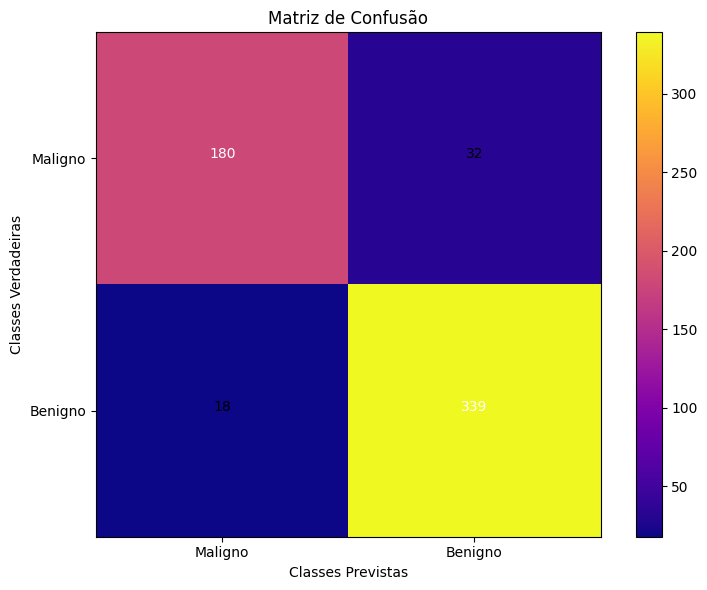

Acurácia média: 91.21%
Precisão média: 91.14%
Recall médio: 89.93%
F1 Score médio: 90.47%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold
from collections import Counter

# 1. Carregar a base de dados
X, y = load_breast_cancer(return_X_y=True)

# 2. Implementar a lógica do classificador KNN
def euclidean_distance_squared(a, b):
    return np.sum((a - b) ** 2)

def knn_predict(X_train, y_train, X_test, k=1):
    predictions = []

    for test_point in X_test:
        # Calcular distâncias ao quadrado para todos os pontos de treinamento
        distances = [euclidean_distance_squared(test_point, train_point) for train_point in X_train]

        # Encontrar os k vizinhos mais próximos
        k_indices = np.argsort(distances)[:k]

        # Obter os rótulos dos vizinhos
        k_nearest_labels = [y_train[i] for i in k_indices]

        # Fazer a previsão com base na maioria dos votos
        most_common = Counter(k_nearest_labels).most_common(1)
        predictions.append(most_common[0][0])

    return np.array(predictions)

# 3. Dividir o conjunto de dados em 10 folds
kf = KFold(n_splits=10)

# 4. Avaliar o modelo com validação cruzada
all_predictions = []
all_true_labels = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Prever as classes para o conjunto de teste
    y_pred = knn_predict(X_train, y_train, X_test, k=1)  # k=1 para KNN
    all_predictions.extend(y_pred)
    all_true_labels.extend(y_test)

# 5. Calcular métricas de desempenho
all_predictions = np.array(all_predictions)
all_true_labels = np.array(all_true_labels)

# Matriz de confusão
confusion_matrix = np.zeros((2, 2), dtype=int)  # 2 classes no breast cancer
for true, pred in zip(all_true_labels, all_predictions):
    confusion_matrix[true, pred] += 1

# 6. Plotar a matriz de confusão
plt.figure(figsize=(8, 6))
plt.imshow(confusion_matrix, interpolation='nearest', cmap='plasma')  # Usando a coloração de roxo a amarelo
plt.title('Matriz de Confusão')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Maligno', 'Benigno'])
plt.yticks(tick_marks, ['Maligno', 'Benigno'])

# Adicionar rótulos aos eixos
plt.xlabel('Classes Previstas')
plt.ylabel('Classes Verdadeiras')

# Adicionar os valores na matriz
thresh = confusion_matrix.max() / 2.
for i, j in np.ndindex(confusion_matrix.shape):
    plt.text(j, i, format(confusion_matrix[i, j], 'd'),
             horizontalalignment="center",
             color="white" if confusion_matrix[i, j] > thresh else "black")

plt.tight_layout()
plt.show()

# 7. Calcular precisão, recall e F1 score
precision = np.diag(confusion_matrix) / np.sum(confusion_matrix, axis=0)  # Precision para cada classe
recall = np.diag(confusion_matrix) / np.sum(confusion_matrix, axis=1)  # Recall para cada classe
f1_scores = 2 * (precision * recall) / (precision + recall)

# 8. Mostrar resultados
accuracy = np.mean(all_predictions == all_true_labels) * 100
print('Acurácia média: {:.2f}%'.format(accuracy))
print('Precisão média: {:.2f}%'.format(np.nanmean(precision) * 100))
print('Recall médio: {:.2f}%'.format(np.nanmean(recall) * 100))
print('F1 Score médio: {:.2f}%'.format(np.nanmean(f1_scores) * 100))
